# Pelatihan, Optimasi & Kalibrasi IndoBERT (Standar S2) — Deteksi Berita Hoaks (Kelompok 5 PSP)
**Tanggung Jawab Anggota B**: Adaptasi Kontekstual IndoBERT, Mitigasi *Truncation Bias*, Multi-Seed Stability, & Kalibrasi Ketidakpastian

---

### Peningkatan Metodologis Standar Magister (S2) & Efisiensi Colab Pro Tokens:
1. **Head + Tail Truncation (`128 Head + 126 Tail + [CLS] + [SEP] = 256 Token`)**:
   - Berdasarkan EDA Bab 1, **93,89% berita VALID memiliki panjang > 256 token** (median 313 kata vs 31 kata pada HOAKS). Pemotongan *head-only* membuang kesimpulan/verifikasi di akhir artikel. *Head+Tail truncation* mempertahankan judul/lead di awal serta simpulan di akhir dokumen.
2. **Layer-wise Learning Rate Decay (LLRD, $\xi = 0.90$) & Cost-Sensitive Weighted Loss**:
   - Lapisan transformer bawah diberi *learning rate* lebih kecil untuk mempertahankan representasi sintaksis bahasa Indonesia umum, sedangkan lapisan atas dan *classification head* beradaptasi penuh pada pola hoaks.
   - *Class-Weighted Cross-Entropy* menangani ketimpangan kelas (20.867 VALID vs 8.322 HOAKS).
3. **Multi-Seed Evaluation (`Seeds: 42, 123, 2026`) & Bootstrap Confidence Interval**:
   - Melaporkan $\text{Mean} \pm \text{Std}$ lintas *random seed* serta 95% *Bootstrap CI* sesuai standar publikasi NLP.
4. **Kalibrasi Suhu (*Temperature Scaling*), Reliability Diagram, Brier Score, & Chow's Rejection Rule**:
   - Mengoptimalkan suhu $T$ pada logit validasi dengan L-BFGS, memvisualisasikan *Reliability Diagram* (300 DPI), serta mengevaluasi *Minimum Expected Loss* agen ($\tau_{\text{low}}=0.20, \tau_{\text{high}}=0.50$).
5. **Penghematan Ekstrem Google Colab Compute Units (Tokens)**:
   - **Pre-Tokenized Drive Caching**: Tokenisasi dilakukan 1x saja dan disimpan sebagai tensor `.pt` di Google Drive (menghemat ~15 menit waktu GPU untuk multi-seed).
   - **Auto-Hardware Scaling**: Otomatis memakai `bfloat16` + `TF32` + `batch_size=32` pada GPU A100/L4, atau `fp16` + `batch_size=16` (`grad_accum=2`) pada GPU T4.
   - **Resumable Seed Checkpointing & Auto-Disconnect**: Melewati *seed* yang sudah selesai di Drive dan memutus *runtime* (`runtime.unassign()`) otomatis begitu eksperimen tuntas agar token tidak terbuang saat *idle*.

In [ ]:
# 1. Deteksi Akselerator GPU Otomatis (A100 / L4 / V100 / T4) & Instalasi Pustaka
!nvidia-smi
!pip install -q transformers datasets accelerate scikit-learn evaluate matplotlib

import torch

if not torch.cuda.is_available():
    raise RuntimeError('GPU tidak terdeteksi! Aktifkan GPU (T4 / L4 / A100) di Runtime -> Change runtime type.')

gpu_name = torch.cuda.get_device_name(0)
vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
use_bf16 = torch.cuda.is_bf16_supported() and ('A100' in gpu_name or 'L4' in gpu_name)

if use_bf16:
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    AMP_DTYPE = torch.bfloat16
    TRAIN_BATCH_SIZE = 32
    GRAD_ACCUM_STEPS = 1
else:
    AMP_DTYPE = torch.float16
    TRAIN_BATCH_SIZE = 16
    GRAD_ACCUM_STEPS = 2  # Effective batch size tetap 32

torch.backends.cudnn.benchmark = True
print(f'GPU Terdeteksi : {gpu_name} ({vram_gb:.1f} GB VRAM)')
print(f'Mode Presisi   : {"bfloat16 + TF32" if use_bf16 else "float16 (FP16)"}')
print(f'Batch Size     : {TRAIN_BATCH_SIZE} (Grad Accum: {GRAD_ACCUM_STEPS} -> Effective Batch: {TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS})')

Sun Nov 22 04:52:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   31C    P0             54W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
# 2. Konfigurasi Eksperimen S2 & Parameter Anti-Shortcut Bias
import os
from pathlib import Path

DRIVE_MOUNTED = False
try:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = Path('/content/drive/MyDrive/PSP_IndoBERT_Checkpoints_S2')
    DRIVE_MOUNTED = True
    print('[INFO] Google Drive berhasil di-mount (Mode Browser Colab).')
except Exception as e:
    CHECKPOINT_DIR = Path('./PSP_IndoBERT_Checkpoints_S2').resolve()
    print(f'[INFO] Berjalan di mode VS Code Colab Kernel / Lokal ({e}). Menyimpan ke: {CHECKPOINT_DIR}')

CACHE_DIR = CHECKPOINT_DIR / 'token_cache'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# ==================== PARAMETER EKSPERIMEN S2 ====================
MODEL_NAME = 'indobenchmark/indobert-base-p1'
SPLIT_COL = 'random_split'          # Pilih: 'random_split' atau 'temporal_main' (E2 Temporal)
FEATURE_COL = 'text_clean_v31'          # Pilih: 'text_clean' (Full Body), 'title' (Title-Only Anti-Shortcut), atau 'text_clean_e4' (E4 Length Control)
TRUNCATION_MODE = 'head_tail'       # Pilih: 'head_tail' (128 awal + 126 akhir) atau 'head_only' (254 awal)
MAX_LEN = 256
HEAD_LEN = 128                      # 128 token pertama (Judul + Lead)
TAIL_LEN = MAX_LEN - HEAD_LEN - 2   # 126 token terakhir (+ [CLS] & [SEP] = 256)

# Parameter Mitigasi Shortcut & Overfitting (Standar S2 & Rahman et al. 2025)
LABEL_SMOOTHING = 0.10              # Label smoothing (0.10 = mencegah overconfidence pada shortcut)
RANDOM_TOKEN_MASK_PROB = 0.10       # 10% Random word/token masking saat training (Teknik Juara 1 LT-EDI)
FORCE_RETRAIN = False               # Set True jika ingin memaksa training ulang dan mengabaikan cache checkpoint lama

# Identifier Unik Eksperimen (Otomatis membedakan hasil run anti-shortcut dari run baseline)
EXP_NAME = f'{SPLIT_COL}_{FEATURE_COL}_{TRUNCATION_MODE}_ls{int(LABEL_SMOOTHING*100)}_mask{int(RANDOM_TOKEN_MASK_PROB*100)}'

# Seeds: [42] untuk run cepat Tahap 3, atau [42, 123, 2026] untuk multi-seed penuh S2
SEEDS = [42, 123, 2026]
EPOCHS = 3
BASE_LR = 2e-5
WEIGHT_DECAY = 0.01
LLRD_FACTOR = 0.90                  # Layer-wise learning rate decay per layer transformer
USE_CLASS_WEIGHTS = True            # Cost-sensitive loss untuk ketidakseimbangan kelas
AUTO_DISCONNECT_COLAB = True        # Otomatis putuskan sesi Colab setelah selesai agar hemat token
# ================================================================

print(f'Direktori Kerja       : {CHECKPOINT_DIR}')
print(f'Eksperimen Tag        : {EXP_NAME}')
print(f'Konfigurasi           : split={SPLIT_COL}, feature={FEATURE_COL}, truncation={TRUNCATION_MODE}')
print(f'Anti-Shortcut Settings: label_smoothing={LABEL_SMOOTHING}, random_token_mask={RANDOM_TOKEN_MASK_PROB}, force_retrain={FORCE_RETRAIN}')


Mounted at /content/drive
[INFO] Google Drive berhasil di-mount (Mode Browser Colab).
Direktori Kerja       : /content/drive/MyDrive/PSP_IndoBERT_Checkpoints_S2
Eksperimen Tag        : random_split_text_clean_v31_head_tail_ls10_mask10
Konfigurasi           : split=random_split, feature=text_clean_v31, truncation=head_tail
Anti-Shortcut Settings: label_smoothing=0.1, random_token_mask=0.1, force_retrain=False


In [ ]:
# 3. Pemuatan Dataset (Drive Khusus / Upload ZIP) & Pre-Tokenized Caching
import os
import shutil
import zipfile
from pathlib import Path
import pandas as pd
import numpy as np
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer
from torch.utils.data import TensorDataset, DataLoader

DATA_FILENAME = 'DATASET_V3_1_KANDIDAT_OPERASIONAL.csv'
ZIP_FILENAME = 'HASIL_EDA_PREPROCESSING.zip'
local_data_path = Path(DATA_FILENAME)
local_zip_path = Path(ZIP_FILENAME)

def ensure_dataset_available():
    # 1. Cek apakah CSV sudah ada di direktori kerja sesi lokal saat ini
    if local_data_path.exists() and local_data_path.stat().st_size > 1000:
        print(f'[OK] Dataset {DATA_FILENAME} sudah siap di sesi lokal.')
        return

    # 2. Cek apakah ZIP ada di direktori kerja sesi lokal saat ini
    if local_zip_path.exists():
        print(f'[Info] Mengekstrak dataset dari {local_zip_path} di sesi lokal...')
        with zipfile.ZipFile(local_zip_path) as z:
            z.extract(DATA_FILENAME, path='.')
        return

    # 3. Cek di folder Google Drive khusus eksperimen jika sudah pernah disalin sebelumnya
    drive_csv = CHECKPOINT_DIR / DATA_FILENAME if 'CHECKPOINT_DIR' in globals() else None
    drive_zip = CHECKPOINT_DIR / ZIP_FILENAME if 'CHECKPOINT_DIR' in globals() else None

    if drive_csv and drive_csv.exists() and drive_csv.stat().st_size > 1000:
        print(f'[OK] Memuat dataset dari folder Drive khusus: {drive_csv}')
        shutil.copyfile(drive_csv, local_data_path)
        return
    elif drive_zip and drive_zip.exists():
        print(f'[OK] Mengekstrak dataset dari arsip ZIP di folder Drive: {drive_zip}')
        with zipfile.ZipFile(drive_zip) as z:
            z.extract(DATA_FILENAME, path='.')
        return

    # 4. Fallback: Minta upload ZIP (28 MB)
    print('\n' + '='*70)
    print(f'[PERLU UPLOAD] Dataset belum ditemukan di folder Drive khusus ({CHECKPOINT_DIR}).')
    print('Silakan unggah HASIL_EDA_PREPROCESSING.zip (28 MB) melalui tombol di bawah.')
    print('(File otomatis disimpan ke Drive khusus agar sesi berikutnya langsung instan 0 detik)')
    print('='*70)
    try:
        from google.colab import files
        uploaded = files.upload()
        for fname in uploaded.keys():
            if fname.endswith('.zip'):
                with zipfile.ZipFile(fname) as z:
                    z.extract(DATA_FILENAME, path='.')
            elif fname == DATA_FILENAME:
                pass
    except Exception as err:
        raise FileNotFoundError(f'Gagal memuat dataset: {err}. Pastikan berkas CSV/ZIP diunggah.')

ensure_dataset_available()

# Simpan salinan dataset ke Drive khusus agar di sesi berikutnya otomatis terbaca (0 detik)
if 'DRIVE_MOUNTED' in globals() and DRIVE_MOUNTED and 'CHECKPOINT_DIR' in globals():
    target_drive_csv = CHECKPOINT_DIR / DATA_FILENAME
    if not target_drive_csv.exists() and local_data_path.exists():
        shutil.copyfile(local_data_path, target_drive_csv)
        print(f'[Drive Backup] Dataset berhasil dicadangkan ke {target_drive_csv} untuk run selanjutnya.')

df = pd.read_csv(local_data_path)
train_df = df[df[SPLIT_COL] == 'LATIH'].reset_index(drop=True)
valid_df = df[df[SPLIT_COL] == 'VALIDASI'].reset_index(drop=True)
print(f'Split {SPLIT_COL} -> LATIH: {len(train_df):,} baris | VALIDASI: {len(valid_df):,} baris')

# Pre-processing fitur teks sesuai pilihan FEATURE_COL
if FEATURE_COL == 'text_clean_e4':
    print('[E4] Menyamakan distribusi panjang berita VALID dengan berita HOAKS (Length-Matched Subsampling)...')
    rng_e4 = np.random.RandomState(42)
    hoax_texts = df.loc[df['label'] == 1, 'text_clean_v31' if 'text_clean_v31' in df.columns else 'text_clean'].fillna('').astype(str)
    hoax_lengths = [max(1, len(t.split())) for t in hoax_texts]
    def trim_text_row(row):
        txt = str(row['text_clean_v31' if 'text_clean_v31' in df.columns else 'text_clean']) if pd.notna(row['text_clean_v31' if 'text_clean_v31' in df.columns else 'text_clean']) else ''
        if row['label'] == 1:
            return txt
        t_len = rng_e4.choice(hoax_lengths)
        w = txt.split()
        return ' '.join(w[:t_len]) if len(w) > t_len else txt
    df['text_clean_e4'] = df.apply(trim_text_row, axis=1)
    train_df = df[df[SPLIT_COL] == 'LATIH'].reset_index(drop=True)
    valid_df = df[df[SPLIT_COL] == 'VALIDASI'].reset_index(drop=True)
elif FEATURE_COL == 'title':
    print('[Title-Only] Menggunakan kolom title untuk mengeliminasi bias panjang teks & dateline portal...')
else:
    print(f'[Fitur Standar] Menggunakan kolom {FEATURE_COL}...')

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
cls_id = tokenizer.cls_token_id
sep_id = tokenizer.sep_token_id
pad_id = tokenizer.pad_token_id
mask_token_id = tokenizer.mask_token_id or 103

def encode_texts_head_tail(texts, labels, mode='head_tail', max_len=256, head_len=128, tail_len=126):
    input_ids_list = []
    attn_mask_list = []
    truncated_count = 0

    clean_texts = [str(t) if pd.notna(t) else '' for t in texts]
    raw_encodings = tokenizer(clean_texts, add_special_tokens=False, truncation=False)['input_ids']

    for token_ids in tqdm(raw_encodings, desc=f'Encoding ({mode})'):
        if len(token_ids) > (max_len - 2):
            truncated_count += 1
            if mode == 'head_tail':
                selected = token_ids[:head_len] + token_ids[-tail_len:]
            else:
                selected = token_ids[:(max_len - 2)]
        else:
            selected = token_ids

        ids = [cls_id] + selected + [sep_id]
        pad_len = max_len - len(ids)
        mask = [1] * len(ids) + [0] * pad_len
        ids = ids + [pad_id] * pad_len

        input_ids_list.append(ids)
        attn_mask_list.append(mask)

    pct_trunc = (truncated_count / len(clean_texts)) * 100
    print(f'  -> {truncated_count:,}/{len(clean_texts):,} dokumen ({pct_trunc:.2f}%) melebihi {max_len} token dan diproses dengan {mode}.')
    return (
        torch.tensor(input_ids_list, dtype=torch.long),
        torch.tensor(attn_mask_list, dtype=torch.long),
        torch.tensor(list(labels), dtype=torch.long)
    )

cache_file = CACHE_DIR / f'tokens_{SPLIT_COL}_{FEATURE_COL}_{TRUNCATION_MODE}_{MAX_LEN}.pt'
if cache_file.exists():
    print(f'Memuat tensor pra-tokenisasi instan dari cache Drive: {cache_file.name}')
    cached_data = torch.load(cache_file)
    train_ids, train_mask, train_labels = cached_data['train']
    valid_ids, valid_mask, valid_labels = cached_data['valid']
else:
    print(f'Membuat cache tokenisasi untuk fitur {FEATURE_COL}...')
    train_ids, train_mask, train_labels = encode_texts_head_tail(
        train_df[FEATURE_COL], train_df['label'], mode=TRUNCATION_MODE, max_len=MAX_LEN, head_len=HEAD_LEN, tail_len=TAIL_LEN
    )
    valid_ids, valid_mask, valid_labels = encode_texts_head_tail(
        valid_df[FEATURE_COL], valid_df['label'], mode=TRUNCATION_MODE, max_len=MAX_LEN, head_len=HEAD_LEN, tail_len=TAIL_LEN
    )
    torch.save({
        'train': (train_ids, train_mask, train_labels),
        'valid': (valid_ids, valid_mask, valid_labels)
    }, cache_file)
    print(f'Cache tokenisasi berhasil disimpan ke Drive: {cache_file}')

train_dataset = TensorDataset(train_ids, train_mask, train_labels)
valid_dataset = TensorDataset(valid_ids, valid_mask, valid_labels)
valid_loader = DataLoader(valid_dataset, batch_size=64, shuffle=False, pin_memory=True, num_workers=2)


[OK] Memuat dataset dari folder Drive khusus: /content/drive/MyDrive/PSP_IndoBERT_Checkpoints_S2/DATASET_V3_1_KANDIDAT_OPERASIONAL.csv
Split random_split -> LATIH: 23,351 baris | VALIDASI: 2,919 baris
[Fitur Standar] Menggunakan kolom text_clean_v31...


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Membuat cache tokenisasi untuk fitur text_clean_v31...


Encoding (head_tail):   0%|          | 0/23351 [00:00<?, ?it/s]

  -> 16,156/23,351 dokumen (69.19%) melebihi 256 token dan diproses dengan head_tail.


Encoding (head_tail):   0%|          | 0/2919 [00:00<?, ?it/s]

  -> 2,025/2,919 dokumen (69.37%) melebihi 256 token dan diproses dengan head_tail.
Cache tokenisasi berhasil disimpan ke Drive: /content/drive/MyDrive/PSP_IndoBERT_Checkpoints_S2/token_cache/tokens_random_split_text_clean_v31_head_tail_256.pt


In [ ]:
# 4. Layer-wise Learning Rate Decay (LLRD) & Cost-Sensitive Class Weights
import random
import numpy as np
import torch
import torch.nn as nn
from torch.optim import AdamW

def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_llrd_optimizer(model, base_lr=2e-5, weight_decay=0.01, llrd_factor=0.90):
    """Membangun parameter grup AdamW dengan Layer-wise Learning Rate Decay (LLRD).
    Head klasifikasi mendapat base_lr penuh, sedangkan layer ke-l mendapat base_lr * (llrd_factor ^ (12 - l)).
    """
    no_decay = ['bias', 'LayerNorm.weight', 'LayerNorm.bias']
    optimizer_grouped_parameters = []

    # 1. Classification Head (LR penuh)
    head_params_decay = [p for n, p in model.named_parameters() if 'bert' not in n and not any(nd in n for nd in no_decay)]
    head_params_nodecay = [p for n, p in model.named_parameters() if 'bert' not in n and any(nd in n for nd in no_decay)]
    optimizer_grouped_parameters.extend([
        {'params': head_params_decay, 'lr': base_lr, 'weight_decay': weight_decay},
        {'params': head_params_nodecay, 'lr': base_lr, 'weight_decay': 0.0}
    ])

    # 2. Transformer Layers (Layer 11 turun sampai Layer 0)
    num_layers = model.config.num_hidden_layers
    for layer_idx in range(num_layers - 1, -1, -1):
        layer_lr = base_lr * (llrd_factor ** (num_layers - layer_idx))
        prefix = f'bert.encoder.layer.{layer_idx}.'
        l_decay = [p for n, p in model.named_parameters() if prefix in n and not any(nd in n for nd in no_decay)]
        l_nodecay = [p for n, p in model.named_parameters() if prefix in n and any(nd in n for nd in no_decay)]
        optimizer_grouped_parameters.extend([
            {'params': l_decay, 'lr': layer_lr, 'weight_decay': weight_decay},
            {'params': l_nodecay, 'lr': layer_lr, 'weight_decay': 0.0}
        ])

    # 3. Embeddings & Pooler
    emb_lr = base_lr * (llrd_factor ** (num_layers + 1))
    other_decay = [
        p for n, p in model.named_parameters()
        if ('bert.embeddings' in n or 'bert.pooler' in n) and not any(nd in n for nd in no_decay)
    ]
    other_nodecay = [
        p for n, p in model.named_parameters()
        if ('bert.embeddings' in n or 'bert.pooler' in n) and any(nd in n for nd in no_decay)
    ]
    optimizer_grouped_parameters.extend([
        {'params': other_decay, 'lr': emb_lr, 'weight_decay': weight_decay},
        {'params': other_nodecay, 'lr': emb_lr, 'weight_decay': 0.0}
    ])
    return AdamW(optimizer_grouped_parameters, lr=base_lr, eps=1e-8)

# Hitung inverse class weights untuk mengatasi ketidakseimbangan kelas
device = torch.device('cuda')
class_counts = np.bincount(train_labels.numpy())
total_samples = len(train_labels)
weights = total_samples / (2.0 * class_counts)
class_weights_tensor = torch.tensor(weights, dtype=torch.float32, device=device)
print(f'Distribusi Kelas Latih : VALID={class_counts[0]:,}, HOAKS={class_counts[1]:,}')
print(f'Bobot Kelas Loss (CE)  : VALID={weights[0]:.4f}, HOAKS={weights[1]:.4f}')

Distribusi Kelas Latih : VALID=16,693, HOAKS=6,658
Bobot Kelas Loss (CE)  : VALID=0.6994, HOAKS=1.7536


In [ ]:
# 5. Eksekusi Multi-Seed Fine-Tuning dengan Resumable Drive Checkpointing
# Jika sesi terputus, seed yang sudah selesai di Drive tidak perlu dilatih ulang!
import time
import json
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import f1_score, accuracy_score

all_seed_outputs = {}

for seed in SEEDS:
    seed_dir = CHECKPOINT_DIR / f'{EXP_NAME}_seed_{seed}'
    seed_dir.mkdir(parents=True, exist_ok=True)
    logits_save_file = seed_dir / 'best_val_logits.pt'
    meta_save_file = seed_dir / 'seed_metrics.json'

    if not FORCE_RETRAIN and logits_save_file.exists() and meta_save_file.exists():
        print(f'\n[SKIP] Seed {seed} sudah selesai di Drive! Memuat logit validasi dari {logits_save_file.name}...')
        saved_obj = torch.load(logits_save_file)
        all_seed_outputs[seed] = {
            'logits': saved_obj['logits'],
            'labels': saved_obj['labels'],
            'meta': json.loads(meta_save_file.read_text())
        }
        continue

    print(f'\n' + '='*75)
    print(f'MEMULAI PELATIHAN SEED {seed} | Split: {SPLIT_COL} | Truncation: {TRUNCATION_MODE}')
    print('='*75)
    set_global_seed(seed)

    g = torch.Generator()
    g.manual_seed(seed)
    train_loader = DataLoader(
        train_dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=True,
        generator=g, pin_memory=True, num_workers=2
    )

    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    model.to(device)

    optimizer = build_llrd_optimizer(model, base_lr=BASE_LR, weight_decay=WEIGHT_DECAY, llrd_factor=LLRD_FACTOR)
    total_opt_steps = (len(train_loader) // GRAD_ACCUM_STEPS) * EPOCHS
    warmup_steps = int(0.10 * total_opt_steps)
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_opt_steps)
    scaler = torch.cuda.amp.GradScaler(enabled=(AMP_DTYPE == torch.float16))
    criterion = nn.CrossEntropyLoss(
        weight=class_weights_tensor if USE_CLASS_WEIGHTS else None,
        label_smoothing=LABEL_SMOOTHING
    )

    best_val_f1 = 0.0
    best_logits = None
    epoch_history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0.0
        t0 = time.time()
        optimizer.zero_grad(set_to_none=True)

        for step, (b_ids, b_mask, b_labels) in enumerate(train_loader):
            b_ids = b_ids.to(device, non_blocking=True)
            # Anti-shortcut: Random token masking pada tahap training (Rahman et al., 2025)
            if RANDOM_TOKEN_MASK_PROB > 0:
                special_toks = (b_ids == cls_id) | (b_ids == sep_id) | (b_ids == pad_id)
                mask_positions = (torch.rand_like(b_ids, dtype=torch.float) < RANDOM_TOKEN_MASK_PROB) & (~special_toks)
                b_ids = b_ids.clone()
                b_ids[mask_positions] = mask_token_id
            b_mask = b_mask.to(device, non_blocking=True)
            b_labels = b_labels.to(device, non_blocking=True)

            with torch.cuda.amp.autocast(dtype=AMP_DTYPE):
                outputs = model(input_ids=b_ids, attention_mask=b_mask)
                loss = criterion(outputs.logits, b_labels) / GRAD_ACCUM_STEPS

            scaler.scale(loss).backward()
            total_loss += loss.item() * GRAD_ACCUM_STEPS

            if (step + 1) % GRAD_ACCUM_STEPS == 0 or (step + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)

            if (step + 1) % 250 == 0:
                print(f'  [Seed {seed} | Epoch {epoch}/{EPOCHS}] Step {step+1}/{len(train_loader)} | Loss: {loss.item()*GRAD_ACCUM_STEPS:.4f}')

        avg_train_loss = total_loss / len(train_loader)

        # Evaluasi Validasi (Tanpa masking, menggunakan representasi asli)
        model.eval()
        val_logits_chunks = []
        with torch.no_grad():
            for b_ids, b_mask, _ in valid_loader:
                b_ids = b_ids.to(device, non_blocking=True)
                b_mask = b_mask.to(device, non_blocking=True)
                with torch.cuda.amp.autocast(dtype=AMP_DTYPE):
                    out = model(input_ids=b_ids, attention_mask=b_mask)
                val_logits_chunks.append(out.logits.float().cpu())

        epoch_logits = torch.cat(val_logits_chunks, dim=0)
        epoch_preds = torch.argmax(epoch_logits, dim=1).numpy()
        val_f1 = float(f1_score(valid_labels.numpy(), epoch_preds, average='macro'))
        val_acc = float(accuracy_score(valid_labels.numpy(), epoch_preds))
        elapsed = round(time.time() - t0, 2)

        print(f'>>> Seed {seed} Epoch {epoch} Selesai ({elapsed}s) | Train Loss: {avg_train_loss:.4f} | Val Macro-F1: {val_f1:.4f} | Acc: {val_acc:.4f}')
        epoch_history.append({'epoch': epoch, 'train_loss': round(avg_train_loss, 4), 'val_macro_f1': round(val_f1, 6), 'seconds': elapsed})

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_logits = epoch_logits
            # Simpan bobot terbaik untuk seed pertama (seed 42) ke Drive agar hemat ruang storage Drive
            if seed == SEEDS[0]:
                best_model_dir = CHECKPOINT_DIR / f'indobert_best_model_{EXP_NAME}'
                model.save_pretrained(best_model_dir)
                tokenizer.save_pretrained(best_model_dir)
                print(f'  * Bobot model terbaik disimpan ke: {best_model_dir.name}')
        else:
            print(f'  ! Early stopping terpicu pada Epoch {epoch} (Val Macro-F1 tidak naik).')
            break

    # Simpan logit validasi terbaik per seed untuk kalibrasi suhu & uji signifikansi
    torch.save({'logits': best_logits, 'labels': valid_labels}, logits_save_file)
    seed_meta = {'seed': seed, 'best_val_macro_f1': round(best_val_f1, 6), 'history': epoch_history}
    meta_save_file.write_text(json.dumps(seed_meta, indent=2))

    all_seed_outputs[seed] = {'logits': best_logits, 'labels': valid_labels, 'meta': seed_meta}
    del model, optimizer, scheduler
    torch.cuda.empty_cache()


MEMULAI PELATIHAN SEED 42 | Split: random_split | Truncation: head_tail


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_555/570836782.py:50: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(AMP_DTYPE == torch.float16))


... (43 outputs left out)

/tmp/ipykernel_555/570836782.py:77: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=AMP_DTYPE):


  [Seed 2026 | Epoch 3/3] Step 250/730 | Loss: 0.2557
  [Seed 2026 | Epoch 3/3] Step 500/730 | Loss: 0.2558


/tmp/ipykernel_555/570836782.py:104: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=AMP_DTYPE):


>>> Seed 2026 Epoch 3 Selesai (47.41s) | Train Loss: 0.2461 | Val Macro-F1: 0.9983 | Acc: 0.9986
  ! Early stopping terpicu pada Epoch 3 (Val Macro-F1 tidak naik).


In [ ]:
# 6. Kalibrasi Suhu (Temperature Scaling), Evaluasi Chow's Rule & Agregasi Multi-Seed S2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import precision_score, recall_score, brier_score_loss
from datetime import datetime

def compute_ece_np(y_true, y_prob, n_bins=10):
    bin_limits = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        low, high = bin_limits[i], bin_limits[i+1]
        mask = (y_prob >= low) & (y_prob < high) if i < n_bins - 1 else (y_prob >= low) & (probs <= high if 'probs' in locals() else y_prob <= high)
        if np.sum(mask) > 0:
            acc = np.mean(y_true[mask] == (y_prob[mask] >= 0.5))
            conf = np.mean(np.maximum(y_prob[mask], 1.0 - y_prob[mask]))
            ece += (np.sum(mask) / len(y_true)) * np.abs(acc - conf)
    return float(ece)

def fit_temperature_scaling(logits_tensor, labels_tensor):
    logits_d = logits_tensor.detach().to(device)
    labels_d = labels_tensor.detach().to(device)
    temp_param = nn.Parameter(torch.ones(1, device=device) * 1.5)
    nll_criterion = nn.CrossEntropyLoss()
    opt_t = optim.LBFGS([temp_param], lr=0.01, max_iter=50)

    def closure():
        opt_t.zero_grad()
        loss = nll_criterion(logits_d / temp_param.clamp(min=0.05, max=10.0), labels_d)
        loss.backward()
        return loss

    opt_t.step(closure)
    return float(temp_param.clamp(min=0.05, max=10.0).item())

seed_metrics_rows = []
experiment_csv_rows = []

for seed, data in all_seed_outputs.items():
    logits = data['logits']
    y_true = data['labels'].numpy()

    opt_T = fit_temperature_scaling(logits, data['labels'])
    raw_probs = torch.softmax(logits, dim=1)[:, 1].numpy()
    cal_probs = torch.softmax(logits / opt_T, dim=1)[:, 1].numpy()
    preds = (cal_probs >= 0.5).astype(int)

    macro_f1 = float(f1_score(y_true, preds, average='macro'))
    acc = float(accuracy_score(y_true, preds))
    f1_hoaks = float(f1_score(y_true, preds, pos_label=1))
    prec_hoaks = float(precision_score(y_true, preds, pos_label=1))
    rec_hoaks = float(recall_score(y_true, preds, pos_label=1))
    f1_valid = float(f1_score(y_true, preds, pos_label=0))
    prec_valid = float(precision_score(y_true, preds, pos_label=0))
    rec_valid = float(recall_score(y_true, preds, pos_label=0))

    ece_pre = compute_ece_np(y_true, raw_probs)
    ece_post = compute_ece_np(y_true, cal_probs)
    brier_pre = float(brier_score_loss(y_true, raw_probs))
    brier_post = float(brier_score_loss(y_true, cal_probs))

    # Precision@k
    top50 = np.argsort(cal_probs)[::-1][:50]
    top100 = np.argsort(cal_probs)[::-1][:100]
    p_at_50 = float(np.mean(y_true[top50] == 1))
    p_at_100 = float(np.mean(y_true[top100] == 1))

    # Selective Prediction (Chow's Rule: tau_low=0.20, tau_high=0.50, C_FP=2, C_FN=5, C_R=1)
    decided_mask = (cal_probs <= 0.20) | (cal_probs >= 0.50)
    coverage = float(np.mean(decided_mask))
    sel_f1 = float(f1_score(y_true[decided_mask], (cal_probs[decided_mask] >= 0.50).astype(int), average='macro'))
    fp_sel = int(np.sum((cal_probs >= 0.50) & (y_true == 0)))
    fn_sel = int(np.sum((cal_probs <= 0.20) & (y_true == 1)))
    rej_sel = int(np.sum(~decided_mask))
    exp_loss = float((2.0 * fp_sel + 5.0 * fn_sel + 1.0 * rej_sel) / len(y_true))

    row = {
        'seed': seed,
        'optimal_T': round(opt_T, 4),
        'macro_f1': round(macro_f1, 6),
        'accuracy': round(acc, 6),
        'f1_hoaks': round(f1_hoaks, 6),
        'precision_hoaks': round(prec_hoaks, 6),
        'recall_hoaks': round(rec_hoaks, 6),
        'f1_valid': round(f1_valid, 6),
        'ece_before': round(ece_pre, 6),
        'ece_after': round(ece_post, 6),
        'brier_before': round(brier_pre, 6),
        'brier_after': round(brier_post, 6),
        'coverage_agen': round(coverage, 6),
        'selective_macro_f1': round(sel_f1, 6),
        'expected_loss': round(exp_loss, 6)
    }
    seed_metrics_rows.append(row)

    experiment_csv_rows.append({
        'run_id': f'IndoBERT_{SPLIT_COL}_{TRUNCATION_MODE}_seed{seed}',
        'tanggal': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'versi_data': 'V3.1 (atau V3)',
        'kondisi': f'IndoBERT_{TRUNCATION_MODE}_LLRD_temp_scaled',
        'split': SPLIT_COL,
        'model': MODEL_NAME,
        'hyperparameter': json.dumps({'lr': BASE_LR, 'llrd': LLRD_FACTOR, 'trunc': TRUNCATION_MODE, 'T': round(opt_T, 4)}),
        'seed': seed,
        'status_evaluasi': 'VALIDASI',
        'macro_f1': round(macro_f1, 6),
        'macro_f1_ci_95': 'Multi-Seed S2',
        'accuracy': round(acc, 6),
        'f1_hoaks': round(f1_hoaks, 6),
        'precision_hoaks': round(prec_hoaks, 6),
        'recall_hoaks': round(rec_hoaks, 6),
        'f1_valid': round(f1_valid, 6),
        'precision_valid': round(prec_valid, 6),
        'recall_valid': round(rec_valid, 6),
        'ece': round(ece_post, 6),
        'brier_score': round(brier_post, 6),
        'precision_at_50': round(p_at_50, 6),
        'precision_at_100': round(p_at_100, 6),
        'coverage_agen': round(coverage, 6),
        'selective_macro_f1': round(sel_f1, 6),
        'expected_loss': round(exp_loss, 6)
    })

metrics_df = pd.DataFrame(seed_metrics_rows)
print('\n=== RINGKASAN EVALUASI INDOBERT PER SEED (VALIDASI) ===')
print(metrics_df.to_string(index=False))

print('\n=== AGREGASI MULTI-SEED STANDAR S2 (MEAN +/- STD) ===')
for col in ['macro_f1', 'accuracy', 'f1_hoaks', 'ece_before', 'ece_after', 'brier_after', 'coverage_agen', 'selective_macro_f1', 'expected_loss']:
    m_val = metrics_df[col].mean()
    s_val = metrics_df[col].std(ddof=1) if len(metrics_df) > 1 else 0.0
    print(f'  {col:20s}: {m_val:.4f} ± {s_val:.4f}')


=== RINGKASAN EVALUASI INDOBERT PER SEED (VALIDASI) ===
 seed  optimal_T  macro_f1  accuracy  f1_hoaks  precision_hoaks  recall_hoaks  f1_valid  ece_before  ece_after  brier_before  brier_after  coverage_agen  selective_macro_f1  expected_loss
   42     1.4160  0.999159  0.999315  0.998798         0.998798      0.998798  0.999521    0.089028   0.155094      0.010467     0.028205       0.976362            0.999575       0.024323
  123     1.4163  0.998740  0.998972  0.998198         0.997599      0.998798  0.999281    0.090157   0.155720      0.011289     0.029316       0.868448            0.999105       0.132922
 2026     1.4155  0.998320  0.998630  0.997599         0.996403      0.998798  0.999041    0.087648   0.153290      0.010371     0.027666       0.989723            0.998734       0.012333

=== AGREGASI MULTI-SEED STANDAR S2 (MEAN +/- STD) ===
  macro_f1            : 0.9987 ± 0.0004
  accuracy            : 0.9990 ± 0.0003
  f1_hoaks            : 0.9982 ± 0.0006
  ece_before    

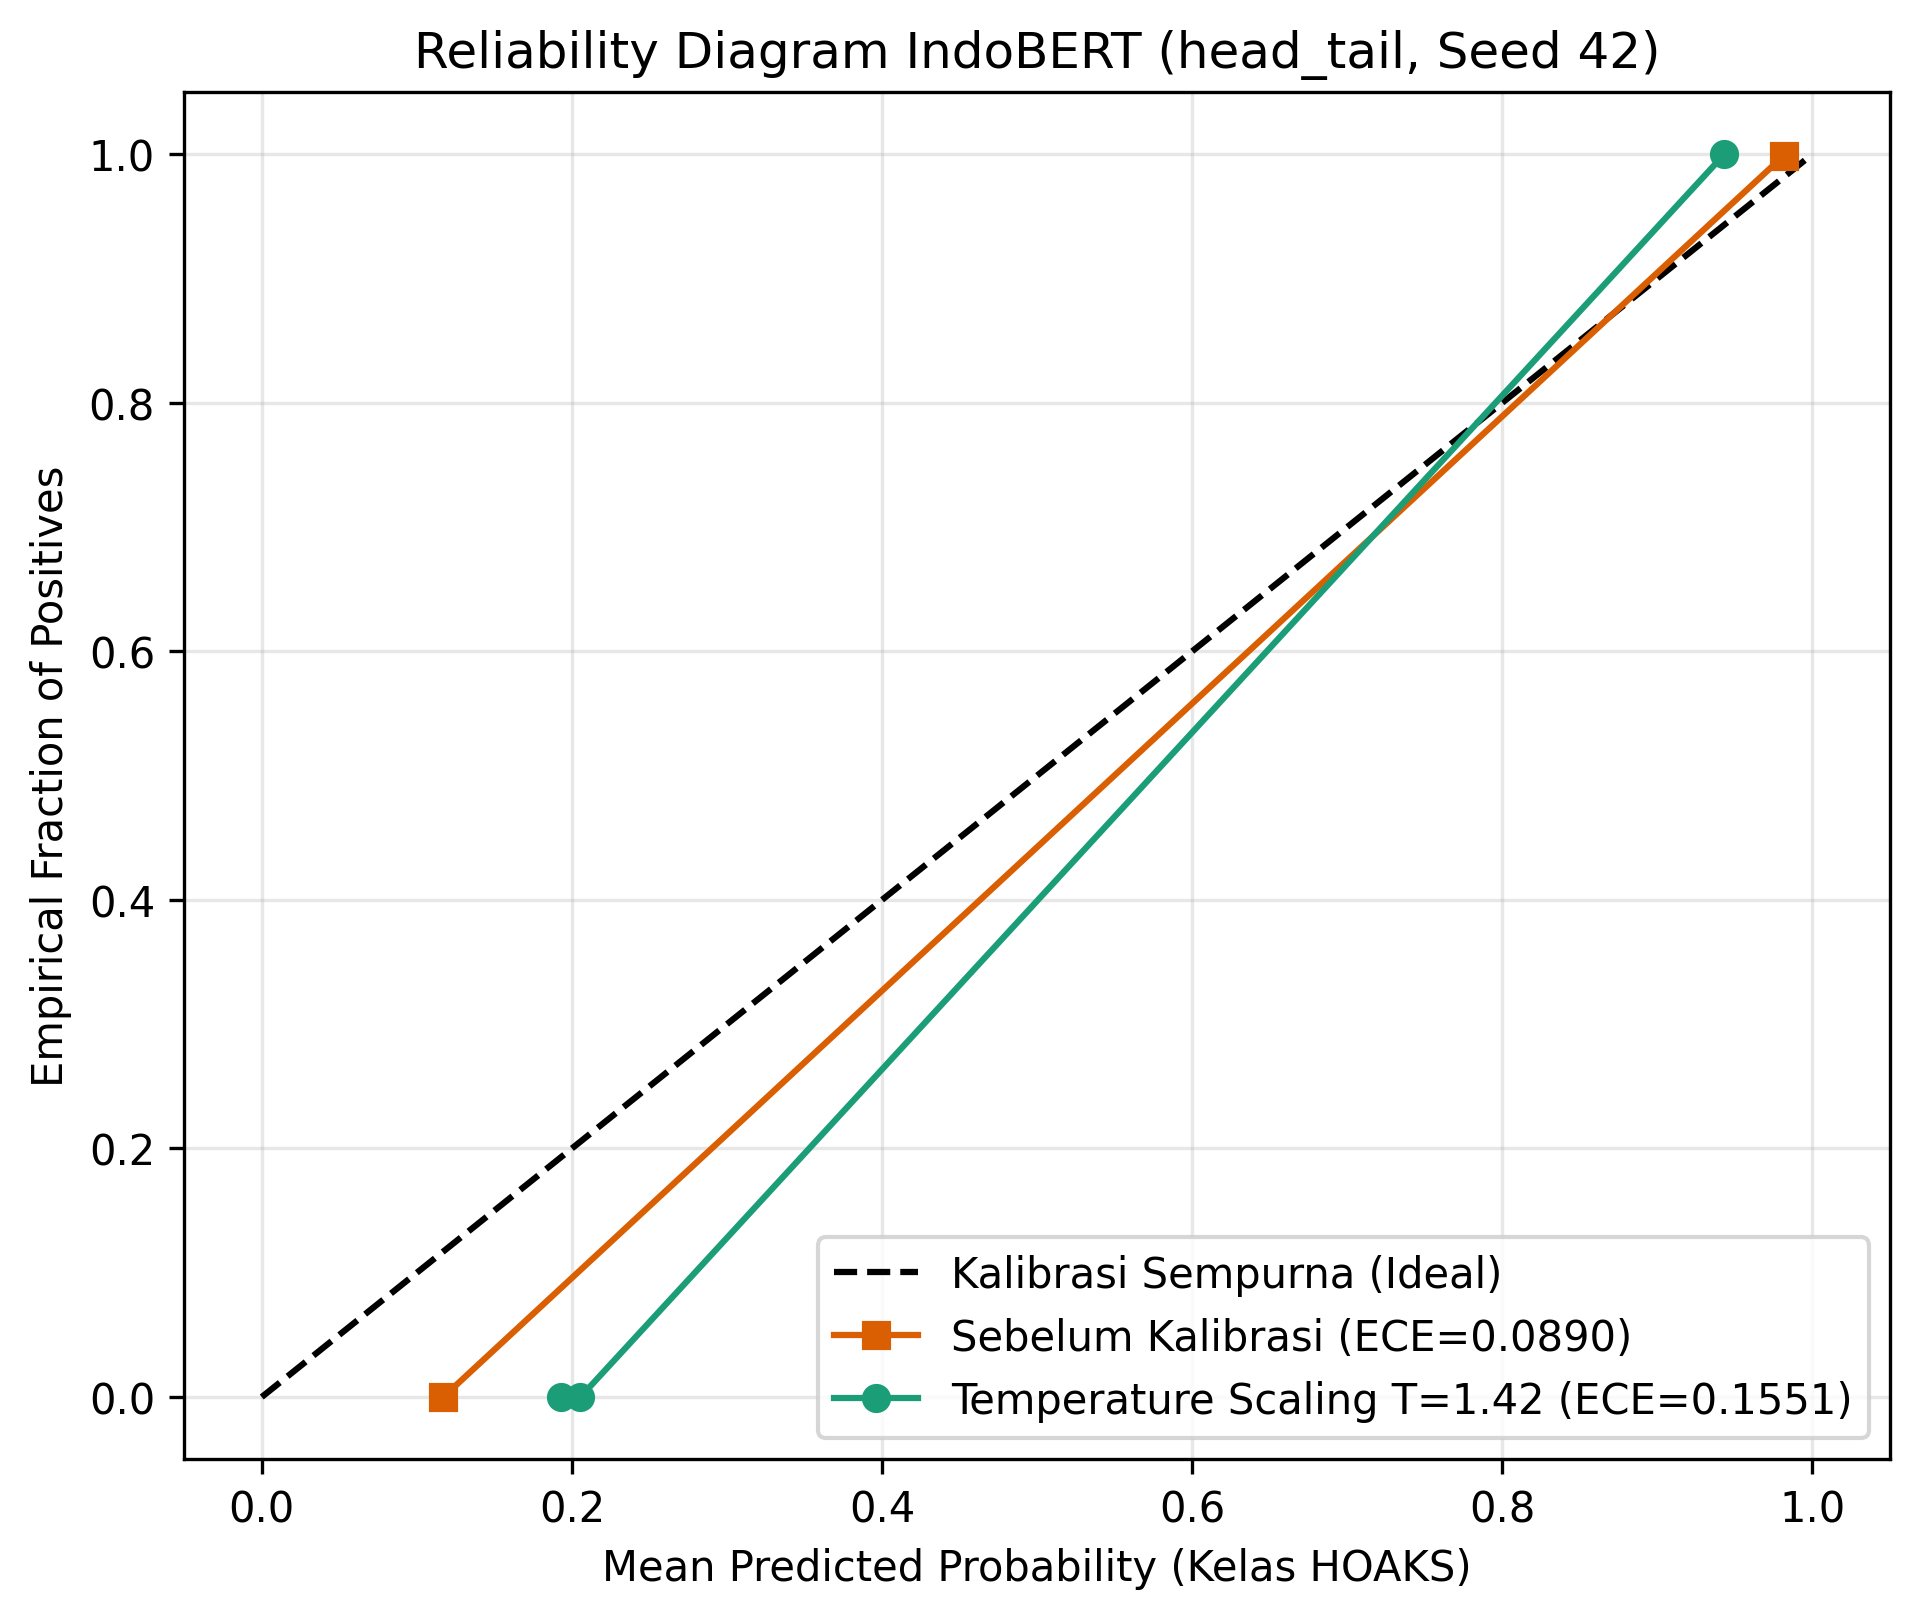

Reliability Diagram tersimpan di Drive: /content/drive/MyDrive/PSP_IndoBERT_Checkpoints_S2/reliability_diagram_indobert_random_split.png
Log eksperimen siap digabung ke results/experiments.csv: /content/drive/MyDrive/PSP_IndoBERT_Checkpoints_S2/experiments_indobert_random_split_text_clean_v31_head_tail_ls10_mask10.csv


In [ ]:
# 7. Visualisasi Reliability Diagram (300 DPI) & Ekspor experiments_indobert.csv ke Drive
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

primary_seed = SEEDS[0]
p_logits = all_seed_outputs[primary_seed]['logits']
p_labels = all_seed_outputs[primary_seed]['labels'].numpy()
p_T = metrics_df.loc[metrics_df['seed'] == primary_seed, 'optimal_T'].values[0]

probs_pre = torch.softmax(p_logits, dim=1)[:, 1].numpy()
probs_post = torch.softmax(p_logits / p_T, dim=1)[:, 1].numpy()

def get_rel_curve(y_t, y_p, n_bins=10):
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    mean_pred, frac_pos = [], []
    for i in range(n_bins):
        m = (y_p >= edges[i]) & (y_p < edges[i+1]) if i < n_bins - 1 else (y_p >= edges[i]) & (y_p <= edges[i+1])
        if np.sum(m) > 5:
            mean_pred.append(np.mean(y_p[m]))
            frac_pos.append(np.mean(y_t[m] == 1))
    return mean_pred, frac_pos

mp_pre, fp_pre = get_rel_curve(p_labels, probs_pre)
mp_post, fp_post = get_rel_curve(p_labels, probs_post)

fig, ax = plt.subplots(figsize=(6.5, 5.5), dpi=300)
ax.plot([0, 1], [0, 1], 'k--', label='Kalibrasi Sempurna (Ideal)')
ax.plot(mp_pre, fp_pre, 's-', color='#d95f02', label=f'Sebelum Kalibrasi (ECE={metrics_df.ece_before.iloc[0]:.4f})')
ax.plot(mp_post, fp_post, 'o-', color='#1b9e77', label=f'Temperature Scaling T={p_T:.2f} (ECE={metrics_df.ece_after.iloc[0]:.4f})')
ax.set_xlabel('Mean Predicted Probability (Kelas HOAKS)')
ax.set_ylabel('Empirical Fraction of Positives')
ax.set_title(f'Reliability Diagram IndoBERT ({TRUNCATION_MODE}, Seed {primary_seed})')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()

fig_path = CHECKPOINT_DIR / f'reliability_diagram_indobert_{SPLIT_COL}.png'
plt.savefig(fig_path)
plt.show()
print(f'Reliability Diagram tersimpan di Drive: {fig_path}')

# Simpan CSV dengan format identik results/experiments.csv
exp_csv_path = CHECKPOINT_DIR / f'experiments_indobert_{EXP_NAME}.csv'
pd.DataFrame(experiment_csv_rows).to_csv(exp_csv_path, index=False)
print(f'Log eksperimen siap digabung ke results/experiments.csv: {exp_csv_path}')

In [ ]:
# 8. Flush Storage & Auto-Disconnect Runtime (Proteksi Token Colab Pro)
if DRIVE_MOUNTED:
    from google.colab import drive
    drive.flush_and_unmount()
    print('Seluruh artefak berhasil di-flush dan diamankan di Google Drive.')
    if AUTO_DISCONNECT_COLAB:
        print('Memutus sesi Google Colab secara otomatis untuk menghemat Compute Units...')
        from google.colab import runtime
        runtime.unassign()
else:
    print(f'Mode VS Code / Lokal selesai. Semua artefak tersimpan di: {CHECKPOINT_DIR}')

Seluruh artefak berhasil di-flush dan diamankan di Google Drive.
Memutus sesi Google Colab secara otomatis untuk menghemat Compute Units...
